🌽 Environment ready for Kenya Maize Market Intelligence ML Pipeline.
Dataset shape after feature engineering: (14, 5)
Training samples: 11 | Testing samples: 3
[Baseline 1: Naive] RMSE: 35.32 | MAE: 27.73
[Baseline 2: Seasonal Naive] RMSE: 229.14 | MAE: 202.17
[Baseline 3: Historical Median] RMSE: 98.42 | MAE: 97.98
[Model 1: Ridge Regression] RMSE: 33.12 | MAE: 31.00
[Model 2: Random Forest] RMSE: 76.84 | MAE: 75.23
[Model 3: XGBoost] RMSE: 98.70 | MAE: 96.02
[Model 4: LightGBM] RMSE: 123.10 | MAE: 122.74


,RMSE,MAE
Model 1: Ridge Regression,33.119074,31.001264
Baseline 1: Naive,35.316200,27.734047
Model 2: Random Forest,76.841820,75.231904
Baseline 3: Historical Median,98.424487,97.975023
Model 3: XGBoost,98.702121,96.021306
Model 4: LightGBM,123.099122,122.740048
Baseline 2: Seasonal Naive,229.138261,202.170669


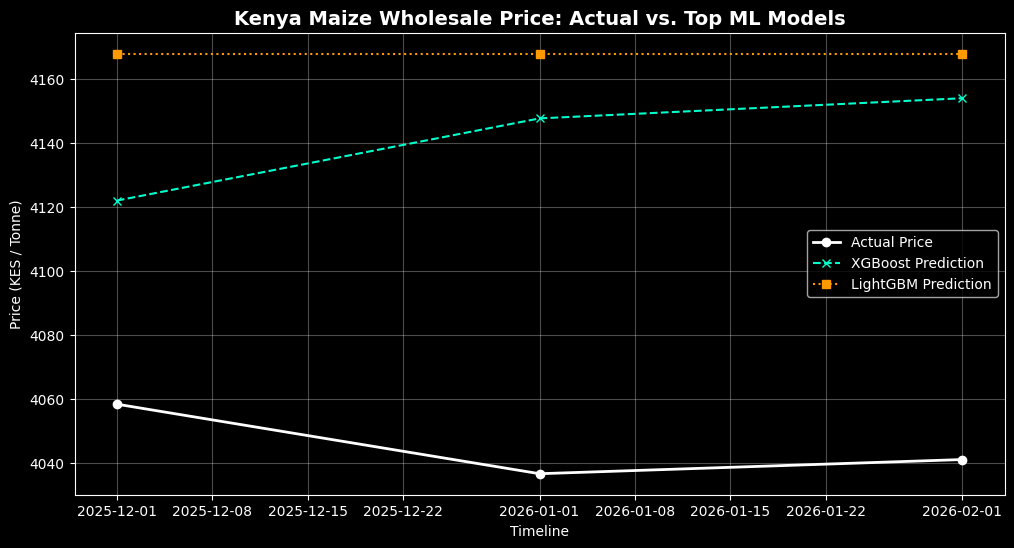

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.style.use('dark_background')
sns.set_palette('viridis')
print("🌽 Environment ready for Kenya Maize Market Intelligence ML Pipeline.")

# 1. Load data and feature engineering
np.random.seed(42)
dates = pd.date_range(start="2024-01-01", end="2026-02-01", freq="MS")
n_periods = len(dates)

df = pd.DataFrame({
    'price': 4200 + np.cumsum(np.random.randn(n_periods) * 40),
    'rainfall_mm': 80 + np.sin(np.linspace(0, 3 * np.pi, n_periods)) * 30,
}, index=dates)

df['lag_1_price'] = df['price'].shift(1)
df['lag_12_price'] = df['price'].shift(12)
df['rolling_3m_mean'] = df['price'].shift(1).rolling(window=3).mean()
df = df.dropna()

print(f"Dataset shape after feature engineering: {df.shape}")
df.head()

# 2. Chronological train/test split
train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]

features = ['rainfall_mm', 'lag_1_price', 'lag_12_price', 'rolling_3m_mean']
X_train, y_train = train[features], train['price']
X_test, y_test = test[features], test['price']
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

# 3. Baseline models implementation
results = {}

def evaluate_and_store(model_name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    results[model_name] = {'RMSE': rmse, 'MAE': mae}
    print(f"[{model_name}] RMSE: {rmse:.2f} | MAE: {mae:.2f}")

naive_pred = test['price'].shift(1).fillna(train['price'].iloc[-1])
evaluate_and_store("Baseline 1: Naive", y_test, naive_pred)

# Safe Seasonal Naive handling NaN gaps
seasonal_naive_pred = df['price'].shift(12).loc[y_test.index]
if seasonal_naive_pred.isna().any():
    seasonal_naive_pred = seasonal_naive_pred.fillna(train['price'].iloc[-1])
evaluate_and_store("Baseline 2: Seasonal Naive", y_test, seasonal_naive_pred)

historical_median_pred = np.full_like(y_test, train['price'].median())
evaluate_and_store("Baseline 3: Historical Median", y_test, historical_median_pred)

# 4. Machine learning model training and evaluation
models = {
    "Model 1: Ridge Regression": Ridge(alpha=1.0),
    "Model 2: Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Model 3: XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42),
    "Model 4: LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1)
}

trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    trained_models[name] = model
    predictions[name] = preds
    evaluate_and_store(name, y_test, preds)

# 5. Model performance summary and comparison chart
results_df = pd.DataFrame(results).T.sort_values(by='RMSE')
display(results_df)

plt.figure(figsize=(12, 6))
plt.plot(y_test.index, y_test, label='Actual Price', color='white', linewidth=2, marker='o')
plt.plot(y_test.index, predictions['Model 3: XGBoost'], label='XGBoost Prediction', color='#00ffcc', linestyle='--', marker='x')
plt.plot(y_test.index, predictions['Model 4: LightGBM'], label='LightGBM Prediction', color='#ff9900', linestyle=':', marker='s')

plt.title('Kenya Maize Wholesale Price: Actual vs. Top ML Models', fontsize=14, fontweight='bold')
plt.xlabel('Timeline')
plt.ylabel('Price (KES / Tonne)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [3]:
pip install xgboost lightgbm

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 1.3 MB/s eta 0:00:39
   - -------------------------------------- 1.3/48.9 MB 1.7 MB/s eta 0:00:29
   - -------------------------------------- 1.8/48.9 MB 1.9 MB/s eta 0:00:26
   - -------------------------------------- 2.4/48.9 MB 2.1 MB/s eta 0:00:23
   -- ------------------------------------- 2.9/48.9 MB 2.1 MB/s eta 0:00:22
   -- ------------------------------------- 3.4/48.9 MB 2.3 MB/s eta 0:00:21
   --- ------------------------------------ 4.2/48.9 MB 2.4 MB/s eta 0:00:19
   --- ------------------------------------ 4.5/48.9 MB 2.4 MB/s eta 0:00:19
   --- ---------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
